### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_HANDPMNRLDDG


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from nptdms import TdmsFile
from scipy import signal
import h5py
import glob, os
import cv2
import seaborn as sns
from roifile import roiread
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
import matplotlib.gridspec as gridspec

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
import sys
sys.path.append("/home/t/tomoyuki-mano1/projects/OL_calcium")
from calfuncs.io import read_sync_ttl
from calfuncs.drg import compute_gOSI, compute_gDSI, compute_simple_oi, get_ett3, \
                         plot_grating_response, plot_polar_graph, plot_grating_response_combined,\
                         FigParams, compute_qi, compute_qi2, bootstrap_selectivity, bootstrap_selectivity3

In [6]:
#### path to relevant files
rootdir = "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520"
recname = "rec8"
savedir = "/bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250318_rec8"

templatefile = os.path.join(rootdir, "2P", recname, "run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif")
roifile = os.path.join(rootdir, "2P", recname, "ROI_transformed_corrected.zip")
dfffile = os.path.join(rootdir, "2P", recname, "dff_ROI_transformed_corrected/DFF.hdf5")
syncfile = os.path.join(rootdir, "sync", f"{recname}.tdms")
drg_table = "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/psychopy/log_rec8_20250318_155228.csv.csv"

In [7]:
### PARAMETERS ###
MIN_OSI = 0.2
MIN_DSI = 0.2
QI_THRESH = 0.08
PVAL_THRESH = 0.05
RESP_AMPLITUDE_THRESH = 0.04

### Load TDMS file

In [8]:
sync_ttl = read_sync_ttl(syncfile)
twop_ttl = sync_ttl["twop_ttl"]
twop_re = sync_ttl["twop_re"]
vis_re = sync_ttl["vis_re"]
print(twop_ttl.shape, twop_re.shape, vis_re.shape)

(1196000,) (18207,) (432,)


### Load DF/F

In [9]:
with h5py.File(dfffile, "r") as hf:
    # Y = hf["dff"][:]
    Y = hf["F"][:]
print(Y.shape) # Y is sampled at 1 kHz

(120, 1196000)


## ETA for drifting gratings (DRG)

In [10]:
dg = pd.read_csv(drg_table)

In [11]:
# fix table for better handling (unit of SF in LCD and projectors are different)
dg.loc[dg["mode"] == "pol_only", "SF"] = 0.004250

display(dg)

,frame,SF,TF,Ori,phase,mode,lum_background_value,pol_background_value,Unnamed: 8
0,0,0.00425,3.0,45,0.386576,lum_only,0,0.74,NaN
1,149,0.00425,3.0,315,0.064144,lum_only,0,0.74,NaN
2,298,0.00425,3.0,0,0.766178,lum_only,0,0.74,NaN
3,447,0.00425,3.0,180,0.599542,lum_only,0,0.74,NaN
4,596,0.00425,3.0,225,0.537128,lum_only,0,0.74,NaN
...,...,...,...,...,...,...,...,...,...
427,447,0.00425,3.0,180,0.292092,pol_only,0,0.74,NaN
428,596,0.00425,3.0,0,0.405843,pol_only,0,0.74,NaN
429,745,0.00425,3.0,90,0.172072,pol_only,0,0.74,NaN
430,894,0.00425,3.0,315,0.058192,pol_only,0,0.74,NaN


In [12]:
E = []
for nid in np.arange(Y.shape[0]):
    # luminance gratings, unpolarized background
    tmp = dg[(dg["mode"]=="lum_only") & (dg["pol_background_value"]==0.74)]
    ett1 = get_ett3(Y, vis_re, tmp, nid, [0, 45, 90, 135, 180, 225, 270, 315], [0.00425], [3],
                    window=[-2000, 4500], baseline_window=[-10000, 10000], subsampling=50)
    ett1["session"] = 0

    # luminance gratings, polarized background
    tmp = dg[(dg["mode"]=="lum_only") & (dg["pol_background_value"]==-1)]
    ett2 = get_ett3(Y, vis_re, tmp, nid, [0, 45, 90, 135, 180, 225, 270, 315], [0.00425], [3],
                   window=[-2000, 4500], baseline_window=[-10000, 10000], subsampling=50)
    ett2["session"] = 1

    # polarization gratings
    tmp = dg[(dg["mode"]=="pol_only")]
    mapping = {
        0: 180,
        45: 135,
        90: 90,
        135: 45,
        180: 0,
        225: 315,
        270: 270,
        315: 225
    }
    tmp.loc[:, 'Ori'] = tmp['Ori'].replace(mapping)
    ett3 = get_ett3(Y, vis_re, tmp, nid, [0, 45, 90, 135, 180, 225, 270, 315], [0.00425], [3],
                    window=[-2000, 4500], baseline_window=[-10000, 10000], subsampling=50)
    ett3["session"] = 2

    ett = pd.concat([ett1, ett2, ett3])
    ett["neuron"] = nid
    ett = ett.set_index(["neuron", "session", "trial", "ori", "sf", "tf", "time"])
    E.append(ett)
E = pd.concat(E)

In [13]:
display(E)

y
neuron session trial ori sf      tf time           
0      0       0     0   0.00425 3  -2000       NaN
                                    -1950       NaN
                                    -1900       NaN
                                    -1850       NaN
                                    -1800       NaN
...                                             ...
119    2       17    315 0.00425 3   4250  0.077427
                                     4300  0.044546
                                     4350  0.113118
                                     4400  0.102828
                                     4450  0.108323

[6739200 rows x 1 columns]

In [ ]:
dt = 1e-2
stimulus = np.zeros(int(6.5/dt), dtype=np.float32)
stimulus[0:int(2.0/dt)] = 0
stimulus[int(2.0/dt):int(4.5/dt)] = 1
stimulus[int(4.5/dt):int(6.5/dt)] = 0

results = []

for nid in np.arange(Y.shape[0]):
    print(nid)
    for SESSION in [0,1,2]:
        qi = compute_qi2(E, nid, SESSION, 3, 0.00425)
        osi, ang_osi, resp_osi, pval_osi = bootstrap_selectivity3(E, nid, SESSION, 3, 0.00425, onset=0, offset=2500,
                                                                  index_func=compute_gOSI, n_iterations=10000, treat_negative_response="offset",
                                                                  reject_strong_negative=True, allowed_minimum=-0.05)
        flag_osi = (osi > MIN_OSI and pval_osi < PVAL_THRESH and resp_osi.max() > RESP_AMPLITUDE_THRESH and qi > QI_THRESH)
        print("OSI", osi, ang_osi, resp_osi.max(), qi, pval_osi)
        dsi, ang_dsi, resp_dsi, pval_dsi = bootstrap_selectivity3(E, nid, SESSION, 3, 0.00425, onset=0, offset=2500,
                                                                  index_func=compute_gDSI, n_iterations=10000, treat_negative_response="offset",
                                                                  reject_strong_negative=True, allowed_minimum=-0.05)
        flag_dsi = (dsi > MIN_DSI and pval_dsi < PVAL_THRESH and resp_dsi.max() > RESP_AMPLITUDE_THRESH and qi > QI_THRESH)
        print("DSI", dsi, ang_dsi, resp_dsi.max(), qi, pval_dsi)
        plot_grating_response(E, nid, SESSION, 3, 0.00425, stimulus_train=stimulus, params=FigParams(size=[6, 2], dpi=300), vmin=-0.1, vmax=0.3)
        results.append({
            "neuron": nid,
            "session": SESSION,
            "qi": qi,
            "osi": osi,
            "resp_osi": resp_osi.tolist(),
            "ang_osi": ang_osi,
            "pval_osi": pval_osi,
            "flag_osi": flag_osi,
            "dsi": dsi,
            "resp_dsi": resp_dsi.tolist(),
            "ang_dsi": ang_dsi,
            "pval_dsi": pval_dsi,
            "flag_dsi": flag_dsi
        })

R = pd.DataFrame(results)

In [15]:
display(R)

,neuron,session,qi,osi,resp_osi,ang_osi,pval_osi,flag_osi,dsi,resp_dsi,ang_dsi,pval_dsi,flag_dsi
0,0,0,0.067425,0.104944,"[0.0232195992609816, -0.00033385613871853443, ...",0,0.8779,False,0.463051,"[0.0232195992609816, -0.00033385613871853443, ...",0,0.0475,False
1,0,1,0.067655,0.287521,"[0.01925290978657594, -0.003343157940079535, -...",0,0.2941,False,0.394075,"[0.01925290978657594, -0.003343157940079535, -...",0,0.0955,False
2,0,2,0.056456,0.109840,"[-0.014134699828171084, 0.013441973584437925, ...",45,0.8531,False,0.304732,"[-0.014134699828171084, 0.013441973584437925, ...",45,0.2408,False
3,1,0,0.086908,0.448140,"[-0.03147455300333621, -0.029549597832133904, ...",135,0.0143,True,0.167957,"[-0.03147455300333621, -0.029549597832133904, ...",315,0.6169,False
4,1,1,0.062313,0.348645,"[0.01584401529518605, 0.011934172007754993, 0....",135,0.1610,False,0.221344,"[0.01584401529518605, 0.011934172007754993, 0....",315,0.4979,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,118,1,0.062284,0.167577,"[0.0004205082832790085, 0.00022795470086739905...",90,0.6914,False,0.112841,"[0.0004205082832790085, 0.00022795470086739905...",270,0.8513,False
356,118,2,0.051714,0.436320,"[-0.0012305838093900276, -9.742281588048043e-0...",90,0.0635,False,0.429097,"[-0.0012305838093900276, -9.742281588048043e-0...",270,0.0703,False
357,119,0,0.057718,0.188444,"[0.0038735673488422984, -0.00709356340018897, ...",90,0.6104,False,0.135840,"[0.0038735673488422984, -0.00709356340018897, ...",90,0.7867,False
358,119,1,0.059819,0.122927,"[-0.03164649272626443, -0.005142006909044501, ...",135,0.8159,False,0.254948,"[-0.03164649272626443, -0.005142006909044501, ...",135,0.3881,False


In [16]:
filtered_df = R[R["flag_osi"] == True]
good_cells = filtered_df["neuron"].unique()

print("Number of OS cells:", len(good_cells))
print("All cells:", len(results)/3)
print("Ratio of OS cells:", len(good_cells)/(len(results)/3))

Number of OS cells: 6
All cells: 120.0
Ratio of OS cells: 0.05


In [17]:
filtered_df = R[R["flag_dsi"] == True]
good_cells = filtered_df["neuron"].unique()

print("Number of DS cells:", len(good_cells))
print("All cells:", len(results)/3)
print("Ratio of DS cells:", len(good_cells)/(len(results)/3))

Number of DS cells: 0
All cells: 120.0
Ratio of DS cells: 0.0


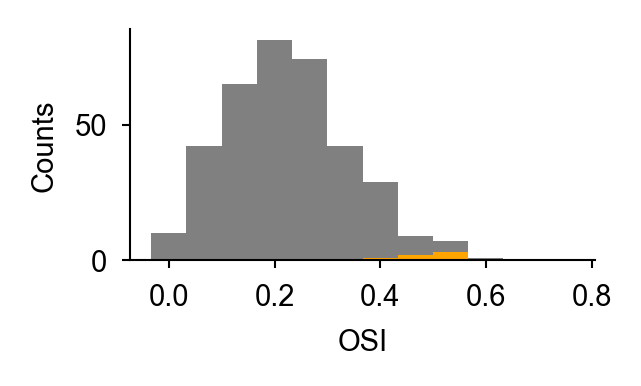

In [18]:
all_samples = R["osi"]
good_samples = R[R["flag_osi"]]["osi"]

fig, ax = plt.subplots(figsize=(2,1), dpi=300)
h1, x1 = np.histogram(all_samples, bins=12, range=[0,0.8])
h2, x2 = np.histogram(good_samples, bins=12, range=[0,0.8])

ax.bar(x1[:-1], h1, width=np.diff(x1), align="center", color="gray", alpha=1)
ax.bar(x2[:-1], h2, width=np.diff(x2), align="center", color="orange", alpha=1)
ax.set_xlabel("OSI")
ax.set_ylabel("Counts")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

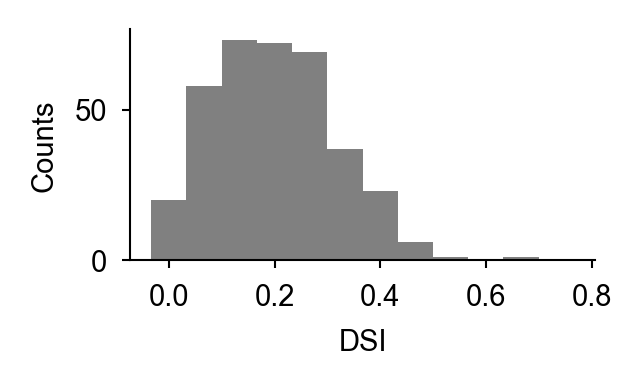

In [19]:
all_samples = R["dsi"]
good_samples = R[R["flag_dsi"]]["dsi"]

fig, ax = plt.subplots(figsize=(2,1), dpi=300)
h1, x1 = np.histogram(all_samples, bins=12, range=[0,0.8])
h2, x2 = np.histogram(good_samples, bins=12, range=[0,0.8])

ax.bar(x1[:-1], h1, width=np.diff(x1), align="center", color="gray", alpha=1)
ax.bar(x2[:-1], h2, width=np.diff(x2), align="center", color="orange", alpha=1)
ax.set_xlabel("DSI")
ax.set_ylabel("Counts")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

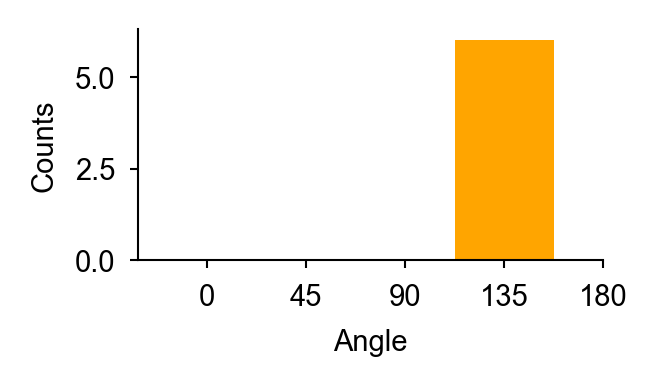

In [20]:
good_samples = R[R["flag_osi"]]["ang_osi"]

fig, ax = plt.subplots(figsize=(2,1), dpi=300)
h2, x2 = np.histogram(good_samples, bins=[0, 45, 90, 135, 180])

ax.bar(x2[:-1], h2, width=np.diff(x2), align="center", color="orange", alpha=1)
ax.set_xlabel("Angle")
ax.set_ylabel("Counts")
ax.set_xticks(x2)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

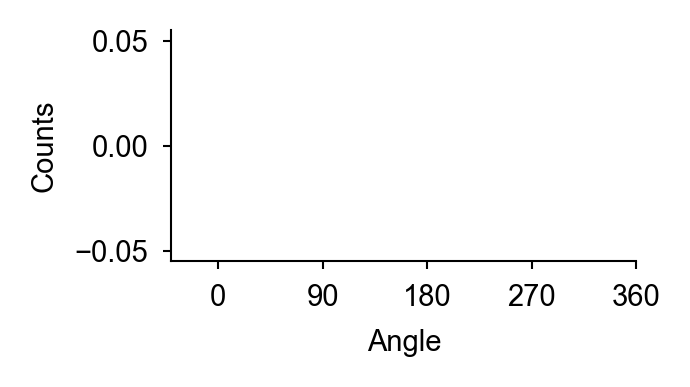

In [21]:
good_samples = R[R["flag_dsi"]]["ang_dsi"]

fig, ax = plt.subplots(figsize=(2,1), dpi=300)
h2, x2 = np.histogram(good_samples, bins=[0, 45, 90, 135, 180, 225, 270, 315, 360])

ax.bar(x2[:-1], h2, width=np.diff(x2), align="center", color="orange", alpha=1)
ax.set_xlabel("Angle")
ax.set_ylabel("Counts")
ax.set_xticks(x2[::2])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

In [22]:
with pd.HDFStore(os.path.join(tmpdir, "response_table.hdf5"), mode='w') as store:
    store.put('E', E)
    store.put('R', R)

/scratch/ipykernel_206216/3957359415.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['resp_osi', 'resp_dsi'], dtype='object')]

  store.put('R', R)


### Show cell location

In [23]:
template = cv2.imread(templatefile, -1)

In [24]:
rois = roiread(roifile)
rois = sorted(rois, key=lambda x: x.name)  # sort the list
contours = [r.subpixel_coordinates.astype("int") for r in rois]
coms = [r.subpixel_coordinates.mean(axis=0) for r in rois]

In [25]:
angles = [0, 45, 90, 135, 180, 225, 270, 315]
[e - 22.5 for e in angles]

[-22.5, 22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5]

In [26]:
from matplotlib.colors import ListedColormap, BoundaryNorm

def show_cells(df, img, contours, session, which, vmin=None, vmax=None):
    # cmap = plt.get_cmap('jet', 8)
    # color_map = {i: cmap(k) for (k, i) in enumerate([0, 45, 90, 135, 180, 225, 270, 315])}
    # cmap = plt.get_cmap('jet')
    # norm = Normalize(vmin=0, vmax=315)
    # sm = ScalarMappable(norm=norm, cmap=cmap)
    angles = [0, 45, 90, 135, 180, 225, 270, 315]
    N = len(angles)
    base_cmap = plt.get_cmap('jet', N)
    colors = [base_cmap(i) for i in range(N)]
    cmap = ListedColormap(colors)
    bounds = [a - 22.5 for a in angles] + [360-22.5]# e.g., center bins at 0, 45, ..., 315
    # bounds = [0, 22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 360]
    norm = BoundaryNorm(bounds, N)

    coms = [e.mean(axis=0) for e in contours]

    if which == "ds":
        k1, k2 = "flag_dsi", "ang_dsi"
    elif which == "os":
        k1, k2 = "flag_osi", "ang_osi"

    filtered_df = df[df["session"] == session]
    colors = []
    for i, r in filtered_df.iterrows():
        if r[k1]:
            color = cmap(norm(r[k2]))
            c = [int(e * 255) for e in color[:3]]  # convert to 0-255 and RGB
        else:
            c = [120,120,120]
        colors.append(c)

    if vmin is None:
        vmin = np.percentile(img, 1)
    if vmax is None:
        vmax = np.percentile(img, 99)

    img = img.copy().astype("float")
    img = 255 * (img - vmin) / (vmax - vmin)
    img = np.clip(img, 0, 255).astype("uint8")
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    for i, c in enumerate(contours):
        cv2.drawContours(img, contours, contourIdx=i, color=colors[i], thickness=2, lineType=cv2.LINE_AA)
        cv2.putText(img, f"{i}", (int(coms[i][0]), int(coms[i][1])), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 255, 255), 1)

    fig, ax = plt.subplots(figsize=(3,3), dpi=300)
    ax.imshow(img)
    ax.axis("off")
    cax = ax.inset_axes([1.04, 0.2, 0.05, 0.6])
    cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, pad=0.04, ticks=angles, spacing="proportional")
    cbar.set_label('Angle (°)')
    # cbar.ax.tick_params(labelsize=7)
    # plt.savefig(os.path.join(tmpdir, "drg_cells_distribution.png"), bbox_inches='tight')
    plt.show()

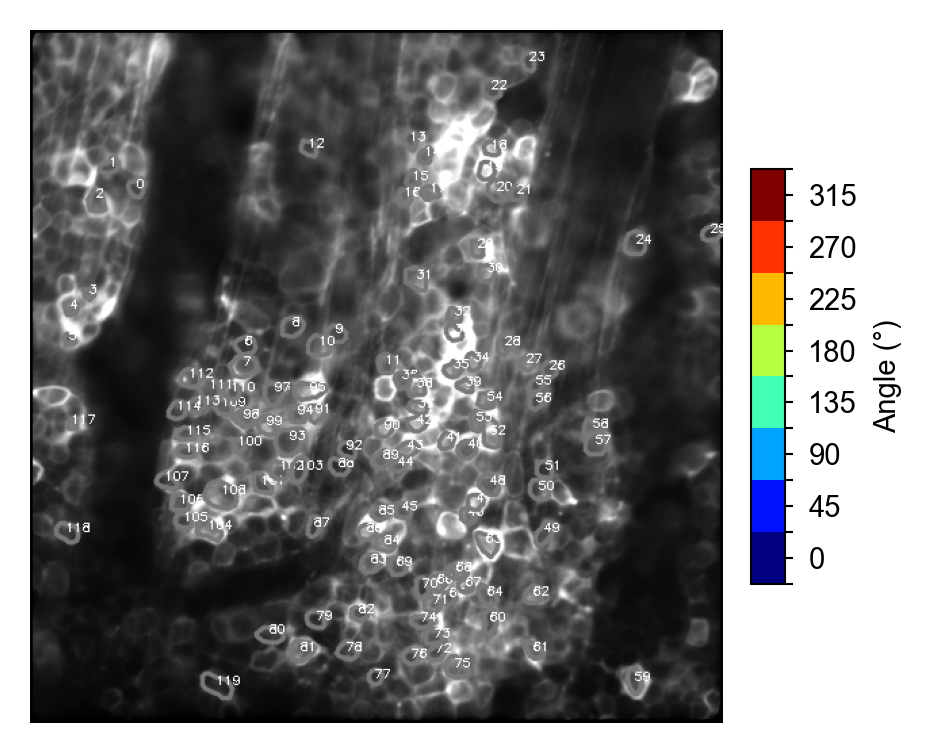

In [27]:
show_cells(R, template, contours, 0, "ds")

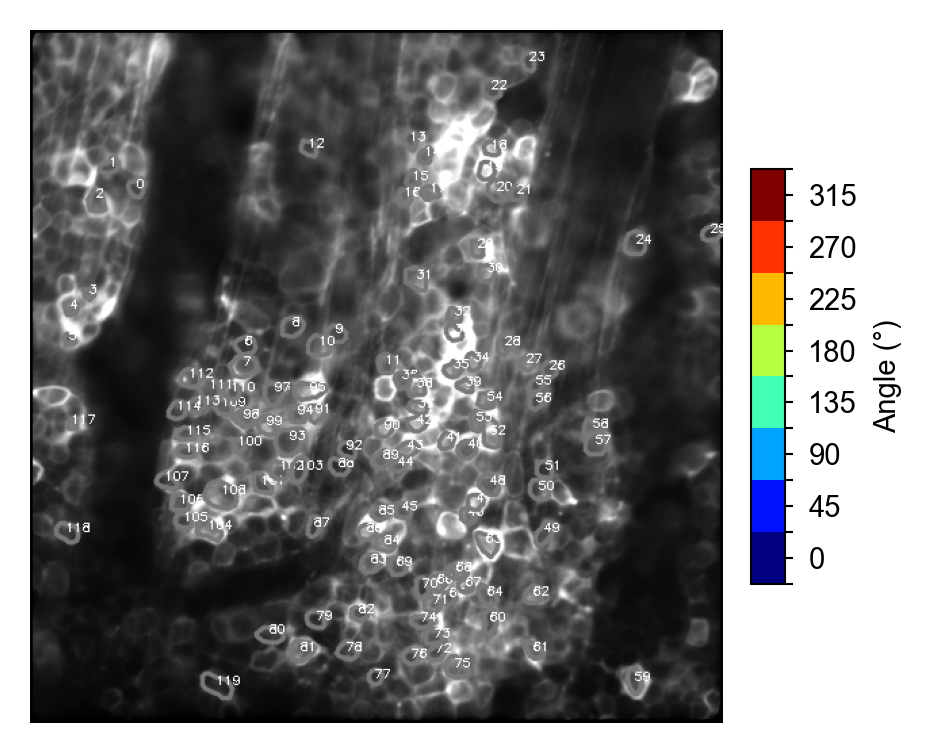

In [28]:
show_cells(R, template, contours, 1, "ds")

In [29]:
all_positive = []
double_positive = []
only_unpol = []
only_pol = []

for n in R["neuron"].unique().tolist():
    df = R[(R["neuron"] == n) & (R["flag_dsi"])]
    p1 =(df["session"] == 0).any()
    p2 =(df["session"] == 1).any()
    p3 =(df["session"] == 2).any()
    if p1 & p2 & p3:
        all_positive.append(n)
    elif p1 & p2:
        double_positive.append(n)
    elif p1:
        only_unpol.append(n)
    elif p2:
        only_pol.append(n)

print(all_positive)
print(double_positive)
print(only_unpol)
print(only_pol)

[]
[]
[]
[]


### Copy data to bucket

In [30]:
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250318_rec8
cp -r /flash/ReiterU/tmp/tomo_HANDPMNRLDDG/* /bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250318_rec8
